# 02 - Clean and validate FD001

This notebook uses the same ingestion and preprocessing functions as `pm-train`. It can run directly from a clean checkout; notebook 01 is explanatory rather than a prerequisite.

Outputs: raw CSVs, validated preprocessed CSVs, and training-derived constant-column metadata. Test RUL uses the supplied ground truth. Neither future readings nor other engines fill missing sensor values.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "predictive_maintenance").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project root or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PM_PROJECT_ROOT", str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from loguru import logger
from predictive_maintenance.config import (
    EXTERNAL_DATA_DIR, RAW_DATA_DIR, INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR,
    RUL_CAP, TREND_WINDOW, SETTINGS,
)

logger.remove()
logger.add(sys.stderr, level="WARNING")
pd.set_option("display.max_columns", 40)
print(f"Project: {ROOT.name} | Python: {sys.version.split()[0]}")


Project: Predictive-Maintenance-for-Sensor-Data | Python: 3.13.9


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


## Import the bundled source files


In [3]:
from predictive_maintenance.data.ingestion import ingest_dataset
from predictive_maintenance.data.preprocessing import preprocess_dataset
from predictive_maintenance.data.validation import validate_dataset

ingest_dataset(
    EXTERNAL_DATA_DIR / "train_FD001.txt", EXTERNAL_DATA_DIR / "test_FD001.txt",
    EXTERNAL_DATA_DIR / "RUL_FD001.txt", RAW_DATA_DIR,
)
constants_path = INTERIM_DATA_DIR / "constant_columns.json"
preprocess_dataset(
    RAW_DATA_DIR / "train_data.csv", INTERIM_DATA_DIR / "train_preprocessed.csv",
    is_train=True, constant_columns_path=constants_path, rul_cap=RUL_CAP,
)
preprocess_dataset(
    RAW_DATA_DIR / "test_data.csv", INTERIM_DATA_DIR / "test_preprocessed.csv",
    is_train=False, constant_columns_path=constants_path,
    rul_path=RAW_DATA_DIR / "rul_data.csv", rul_cap=RUL_CAP,
)
train = pd.read_csv(INTERIM_DATA_DIR / "train_preprocessed.csv")
test = pd.read_csv(INTERIM_DATA_DIR / "test_preprocessed.csv")
validate_dataset(train)
validate_dataset(test)
assert train.columns.tolist() == test.columns.tolist()
display(pd.DataFrame({"split": ["train", "test"], "rows": [len(train), len(test)],
                      "columns": [train.shape[1], test.shape[1]]}))


,split,rows,columns
0,train,20631,20
1,test,13096,20


## Check training-derived column filtering


In [4]:
import json

constant_columns = json.loads(constants_path.read_text())
print("Removed from both splits:", constant_columns)
assert {"unit", "cycle", "RUL"}.issubset(train.columns)
assert not set(constant_columns).intersection(train.columns)
display(train.head())


Removed from both splits: ['os_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


,unit,cycle,os_1,os_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,125
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,125
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,125
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,125


## Verify the target construction

Training trajectories end at RUL zero. Test trajectories end at the provided remaining life, capped using the same ceiling as training.


In [5]:
truth = pd.read_csv(RAW_DATA_DIR / "rul_data.csv").assign(
    unit=lambda frame: np.arange(1, len(frame) + 1)
).set_index("unit")["RUL"]
last_test = test.loc[test.groupby("unit").cycle.idxmax()].set_index("unit").sort_index()
expected = truth.reindex(last_test.index)
if RUL_CAP is not None:
    expected = expected.clip(upper=RUL_CAP)
np.testing.assert_allclose(last_test.RUL, expected)
assert (train.groupby("unit").tail(1).RUL == 0).all()
display(last_test[["cycle", "RUL"]].head(10))


,cycle,RUL
unit,,
1,31,112
2,49,98
3,126,69
4,106,82
5,98,91
6,105,93
7,160,91
8,166,95
9,55,111


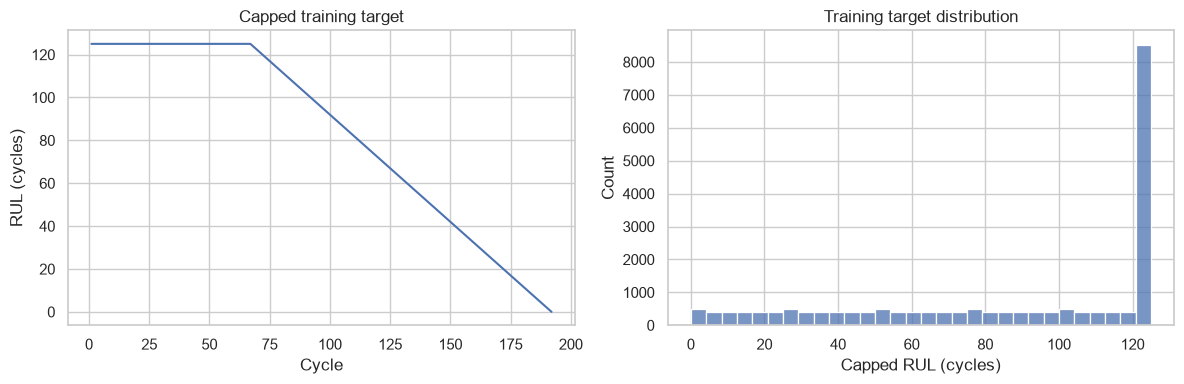

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
engine = train.loc[train.unit == train.unit.min()]
axes[0].plot(engine.cycle, engine.RUL)
axes[0].set(title="Capped training target", xlabel="Cycle", ylabel="RUL (cycles)")
sns.histplot(train.RUL, bins=30, ax=axes[1])
axes[1].set(title="Training target distribution", xlabel="Capped RUL (cycles)")
plt.tight_layout()
plt.show()


**Next:** `03_feature_engineering.ipynb`. Scaling is fitted inside the estimator on training folds, rather than on the complete dataset here.
